In [ ]:
import pandas as pd
file_path = r"C:\Users\user\Downloads\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv"

try:
    df = pd.read_csv(file_path)
    print("Succès ! Le dataset est chargé.")
    print(df.head())
except Exception as e:
    print(f"Erreur lors du chargement : {e}")

Succès ! Le dataset est chargé.
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  


In [15]:
# Vérifier l'équilibre des classes (pannes vs normal)
print("--- Répartition des pannes ---")
print(df['Machine failure'].value_counts())

# Statistiques descriptives pour voir les valeurs aberrantes
print("\n--- Statistiques clés ---")
print(df.describe())

# Vérifier les valeurs manquantes 
print("\n--- Valeurs manquantes ---")
print(df.isnull().sum())

--- Répartition des pannes ---
Machine failure
0    9661
1     339
Name: count, dtype: int64

--- Statistiques clés ---
               UDI  Air temperature [K]  Process temperature [K]  \
count  10000.00000         10000.000000             10000.000000   
mean    5000.50000           300.004930               310.005560   
std     2886.89568             2.000259                 1.483734   
min        1.00000           295.300000               305.700000   
25%     2500.75000           298.300000               308.800000   
50%     5000.50000           300.100000               310.100000   
75%     7500.25000           301.500000               311.100000   
max    10000.00000           304.500000               313.800000   

       Rotational speed [rpm]   Torque [Nm]  Tool wear [min]  Machine failure  \
count            10000.000000  10000.000000     10000.000000     10000.000000   
mean              1538.776100     39.986910       107.951000         0.033900   
std                179.2

In [16]:
#Le value_counts() révèle un déséquilibre de classe massif (très peu de pannes par rapport aux machines saines). 
#C'est pour cela on va utiliser SMOTE par la suite 
#on va egalement recher des valeurs suspectes (?, null....) et verifier des zéros physiques.

In [17]:
import numpy as np

# Définir ce qu'on considère comme des "valeurs suspectes"
suspect_values = ['', ' ', 'NULL', 'null', 'None', 'nan', 'N/A', '?', '-']

print("--- Analyse des valeurs suspectes (Hors NaN classiques) ---")

for col in df.columns:
    # On vérifie uniquement les colonnes de type 'object' (texte) 
    # ou on convertit tout en string pour la recherche
    counts = df[col].astype(str).str.strip().isin(suspect_values).sum()
    
    if counts > 0:
        print(f"⚠️ Colonne '{col}' : {counts} valeurs suspectes trouvées.")
    else:
        print(f"✅ Colonne '{col}' : OK")

# Vérification des zéros suspects (ex: une température à 0 K est impossible)
# Pour les colonnes physiques, un 0 est souvent une erreur de capteur
cols_physiques = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]']
zeros = (df[cols_physiques] == 0).sum()
print("\n--- Vérification des zéros physiques ---")
print(zeros)

--- Analyse des valeurs suspectes (Hors NaN classiques) ---
✅ Colonne 'UDI' : OK
✅ Colonne 'Product ID' : OK
✅ Colonne 'Type' : OK
✅ Colonne 'Air temperature [K]' : OK
✅ Colonne 'Process temperature [K]' : OK
✅ Colonne 'Rotational speed [rpm]' : OK
✅ Colonne 'Torque [Nm]' : OK
✅ Colonne 'Tool wear [min]' : OK
✅ Colonne 'Machine failure' : OK
✅ Colonne 'TWF' : OK
✅ Colonne 'HDF' : OK
✅ Colonne 'PWF' : OK
✅ Colonne 'OSF' : OK
✅ Colonne 'RNF' : OK

--- Vérification des zéros physiques ---
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
dtype: int64


In [18]:
#on va identifier quelles variables sont liées entre elles

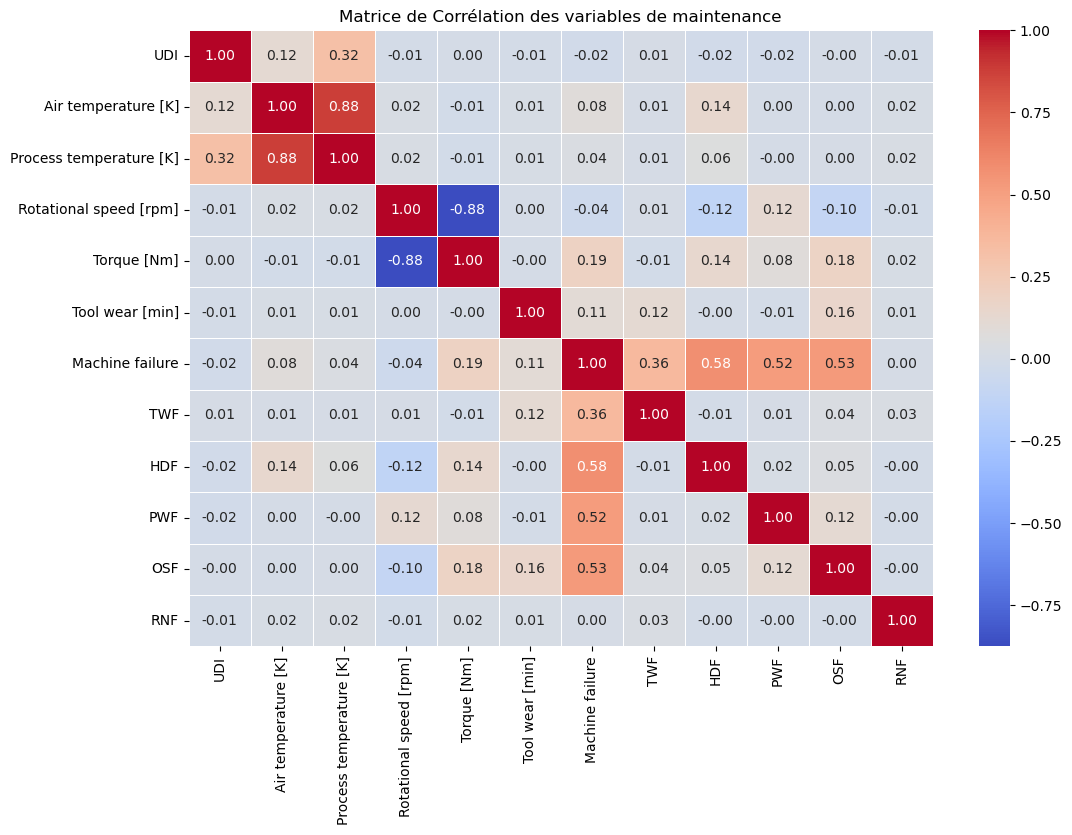

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# matrice de corrélation
corr_matrix = df.select_dtypes(include=[np.number]).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matrice de Corrélation des variables de maintenance")
plt.show()

In [ ]:
#On remarque souvent que le Couple (Torque) et la Vitesse (Rotational speed) sont fortement liés
#Cela aide à comprendre la physique de la machine : si la vitesse chute et le couple monte, la machine force, ce qui peut annoncer une panne

In [20]:
#On observe aussi une corrélation quasi-parfaite (0.88) entre les températures de l'air et du processus, 
#Concernant la cible Machine failure, 
#elle est surtout liée aux défaillances spécifiques comme l'échauffement (HDF à 0.58), la puissance (PWF à 0.52) et la surcharge (OSF à 0.53). 
#En revanche, l'usure de l'outil (Tool wear) et le couple semblent être les variables physiques directes ayant le plus d'influence sur une panne générale
#bien que leur impact individuel paraisse modéré (0.11 et 0.19).

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Copie du dataframe pour ne pas altérer l'original
df_ml = df.copy()

# 2. Encodage de la colonne 'Type' (L=0, M=1, H=2 par exemple)
le = LabelEncoder()
df_ml['Type'] = le.fit_transform(df_ml['Type'])

# 3. Sélection des caractéristiques (Features) et de la cible (Target)
# On retire 'UDI' et 'Product ID' qui sont juste des identifiants sans valeur prédictive
# On retire aussi les types de pannes spécifiques (TWF, HDF...) pour ne pas "tricher"
X = df_ml.drop(['UDI', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'], axis=1)
y = df_ml['Machine failure']

# 4. Division 80% entraînement / 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entraînement : {X_train.shape[0]} échantillons")
print(f"Test : {X_test.shape[0]} échantillons")

Entraînement : 8000 échantillons
Test : 2000 échantillons


In [ ]:
#le dataset initial est "déséquilibré" on a environ 97% de machines saines et seulement 3% de pannes.
#Le problème que si on entraîne un modèle directement il aura 97% de précision tout en étant totalement inutile car il ne détectera aucune panne réelle.
#La solution (SMOTE) est une technique qui ne se contente pas de copier les pannes existantes elle crée de nouvelles pannes synthétiques 
#(artificielles mais réalistes) en créant des points mathématiques entre les pannes réelles.

Avant SMOTE : 271 pannes
Après SMOTE : 7729 pannes (Équilibre 50/50)

--- Nouveau Rapport de Classification (avec SMOTE) ---
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.43      0.72      0.54        68

    accuracy                           0.96      2000
   macro avg       0.71      0.84      0.76      2000
weighted avg       0.97      0.96      0.96      2000



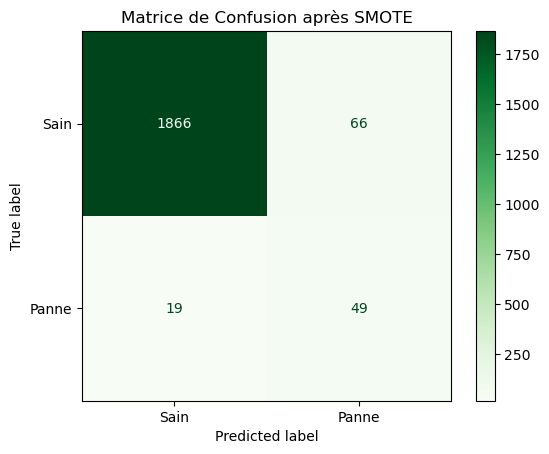

In [23]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Création du générateur SMOTE
sm = SMOTE(random_state=42)

# 2. On rééquilibre uniquement l'ensemble d'ENTRAÎNEMENT 
# (On ne touche jamais au test pour garder une évaluation réelle)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print(f"Avant SMOTE : {sum(y_train == 1)} pannes")
print(f"Après SMOTE : {sum(y_train_res == 1)} pannes (Équilibre 50/50)")

# 3. Ré-entraînement du modèle
model_smote = RandomForestClassifier(n_estimators=100, random_state=42)
model_smote.fit(X_train_res, y_train_res)

# 4. Évaluation
y_pred_smote = model_smote.predict(X_test)

print("\n--- Nouveau Rapport de Classification (avec SMOTE) ---")
print(classification_report(y_test, y_pred_smote))

# 5. Affichage de la nouvelle Matrice de Confusion
cm_smote = confusion_matrix(y_test, y_pred_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_smote, display_labels=['Sain', 'Panne'])
disp.plot(cmap='Greens')
plt.title("Matrice de Confusion après SMOTE")
plt.show()

In [12]:
import joblib

# Ces objets (model_smote et le) doivent exister dans ta mémoire Python actuelle
try:
    # Sauvegarde du modèle
    joblib.dump(model_smote, 'modele_maintenance_predictive.pkl')
    # Sauvegarde de l'encodeur
    joblib.dump(le, 'label_encoder_type.pkl')
    print("Succès ! Les deux fichiers .pkl ont été créés là où ton script Python s'exécute.")
except NameError as e:
    print(f"Erreur : Tu dois d'abord entraîner ton modèle (model_smote) et créer ton encodeur (le). {e}")

Succès ! Les deux fichiers .pkl ont été créés là où ton script Python s'exécute.


In [ ]:
#après avoir entraîné notre modele par SMOTE noous avons l'enregistré dans un fichier .pkl via joblib
#pour l'utiise avec streamlit 